# Fase 1 · Perfilado de SECOP II - Contratos Electrónicos

**Objetivo.** Ver cómo vienen realmente los datos antes de definir reglas de calidad. Este notebook no mide todavía un DQ Score: describe lo que hay y deja una lista de hallazgos que en la Fase 2 se convierten en reglas.

**Datos.** Snapshot congelado de 50.000 contratos descargado el 27-10-2026 de [datos.gov.co](https://www.datos.gov.co/d/jbjy-vk9h) (licencia CC BY-SA 4.0), sin datos personales. Ver el README de la carpeta para el detalle.

**Decisión de lectura.** Todas las columnas se leen como texto, tal como llegan de la API. Así se ven los valores crudos (por ejemplo `"No definido"` en vez de un nulo) antes de convertir tipos.

In [1]:
import pathlib

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

DATA = pathlib.Path("../data/secop2_contratos_2026-10-27_50000.parquet")
OUT = pathlib.Path("../outputs")
OUT.mkdir(exist_ok=True)
FECHA_CORTE = pd.Timestamp("2026-10-27")

# Paleta: azul para la serie principal, naranja para la segunda; texto en gris oscuro.
AZUL, NARANJA, TEXTO, GRIS = "#2a78d6", "#eb6834", "#52514e", "#d9d8d4"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRIS, "axes.labelcolor": TEXTO, "xtick.color": TEXTO,
    "ytick.color": TEXTO, "axes.grid": True, "grid.color": "#eeeeec", "axes.axisbelow": True,
})

df = pd.read_parquet(DATA)
df.shape

(50000, 97)

## 1. Visión general

In [2]:
texto = [c for c in df.columns if pd.api.types.is_string_dtype(df[c])]
banderas = [c for c in df.columns if c.endswith("_informado")]
print(f"{len(df):,} contratos · {df.shape[1]} columnas")
print(f"  {len(texto)} de texto (todas las de la fuente)")
print(f"  {len(banderas)} banderas *_informado que reemplazan columnas personales")
print(f"  2 derivadas del documento del proveedor (longitud, solo dígitos)")

50,000 contratos · 97 columnas
  77 de texto (todas las de la fuente)
  18 banderas *_informado que reemplazan columnas personales
  2 derivadas del documento del proveedor (longitud, solo dígitos)


## 2. Revisión de datos personales

Antes de publicar la muestra se revisó el CSV original con un escaneo de patrones, mostrando solo porcentajes y nunca valores. Para cada columna se midió qué parte de los valores informados es un número de 6 a 10 dígitos (forma de una cédula), contiene un correo o parece una dirección.

| Columna en la fuente | Patrón encontrado | Tratamiento |
|---|---|---|
| `documento_proveedor` | 99,7 % números tipo cédula; el 85 % de los proveedores son personas naturales | Seudónimo (HMAC con sal) si no es NIT; se conservan longitud y si es solo dígitos |
| `proveedor_adjudicado` | Nombre de la persona cuando no es NIT | Reemplazado por `[persona natural]` |
| `n_mero_de_documento_*` (ordenador del gasto, supervisor, ordenador de pago) | 92-96 % números tipo cédula | Bandera `_informado` |
| `identificaci_n_representante_legal` | 35 % números tipo cédula | Bandera `_informado` |
| `domicilio_representante_legal` | 74 % direcciones | Bandera `_informado` |
| `n_mero_de_cuenta` | 25 % números tipo cuenta | Bandera `_informado` |
| nombres, género, nacionalidad, banco y tipo de cuenta de esas personas | Atributos de la misma persona | Bandera `_informado` |
| `nit_entidad`, `codigo_entidad`, valores, `codigo_proveedor` | Números, pero de entidades públicas, montos o códigos internos de la plataforma | Se conservan |
| `direcci_n_de_ejecuci_n_del_contrato` | 81 % direcciones, de ejecución del contrato (normalmente la sede de la entidad) | Se conserva |

Límite conocido: no es una anonimización. La fuente es pública y `id_contrato` lleva al registro original en SECOP; el objetivo es no republicar los datos personales en claro.

La celda siguiente comprueba que en la muestra publicada no quedan documentos en claro en los campos de texto libre.

In [3]:
libres = ["objeto_del_contrato", "descripcion_del_proceso", "proveedor_adjudicado", "nombre_entidad"]
residual = pd.DataFrame({
    c: {"con_numero_tipo_cedula_%": round(df[c].str.contains(r"\b\d{7,10}\b").mean() * 100, 2),
        "con_correo_%": round(df[c].str.contains("@").mean() * 100, 2)}
    for c in libres
}).T
residual

,con_numero_tipo_cedula_%,con_correo_%
objeto_del_contrato,4.04,0.00
descripcion_del_proceso,2.71,0.00
proveedor_adjudicado,0.01,0.02
nombre_entidad,0.00,0.00


Entre el 3 % y el 4 % de los textos libres contiene un número de 7 a 10 dígitos. Para saber si son cédulas se cruzaron, sobre el CSV original y solo con conteos, contra los documentos de los proveedores que son personas: **ninguno coincide**. Son números de contratos, resoluciones o NIT de empresas (2 textos citan el NIT de su propio proveedor). El riesgo residual en esta muestra es bajo, pero en otra muestra habría que repetir el cruce.

## 3. Completitud: vacíos reales y nulos disfrazados

Un campo puede estar vacío de dos maneras: sin texto (`""`) o con un texto que significa "no hay dato" (`"No definido"`, `"No aplica"`). La segunda es más peligrosa porque un conteo de nulos normal no la detecta.

In [4]:
DISFRAZADOS = {"no definido", "no aplica", "n/a", "na", "null", "sin descripcion",
               "no especificado", "sin información", "sin informacion"}

def completitud(col: pd.Series) -> dict:
    s = col.str.strip()
    vacio = (s == "").mean()
    disfrazado = s.str.lower().isin(DISFRAZADOS).mean()
    return {"vacio_%": vacio * 100, "disfrazado_%": disfrazado * 100,
            "informado_%": (1 - vacio - disfrazado) * 100}

comp = pd.DataFrame({c: completitud(df[c]) for c in texto}).T.round(1)
comp = comp.sort_values("informado_%")
print(f"Columnas con algún faltante: {(comp['informado_%'] < 100).sum()} de {len(texto)}")
print(f"Columnas con menos de 50 % informado: {(comp['informado_%'] < 50).sum()}")
comp[comp["informado_%"] < 100]

Columnas con algún faltante: 30 de 77
Columnas con menos de 50 % informado: 15


,vacio_%,disfrazado_%,informado_%
fecha_inicio_obligaciones_posconsumo,100.0,0.0,0.0
fecha_fin_obligaciones_posconsumo,100.0,0.0,0.0
fecha_inicio_reversi_n,100.0,0.0,0.0
fecha_fin_reversi_n,100.0,0.0,0.0
requisitos_ambientales_en_las_especificaciones_t_cnicas,0.0,99.9,0.1
criterios_ambientales_en_la_evaluaci_n_de_las_ofertas,0.0,99.9,0.1
obligaciones_contractuales_o_poscontractuales_a_nivel_ambiental,0.0,99.9,0.1
uso_de_etiquetado_ecol_gico,0.0,99.9,0.1
descripcion_documentos_tipo,0.0,99.6,0.4
puntos_del_acuerdo,0.0,99.4,0.6


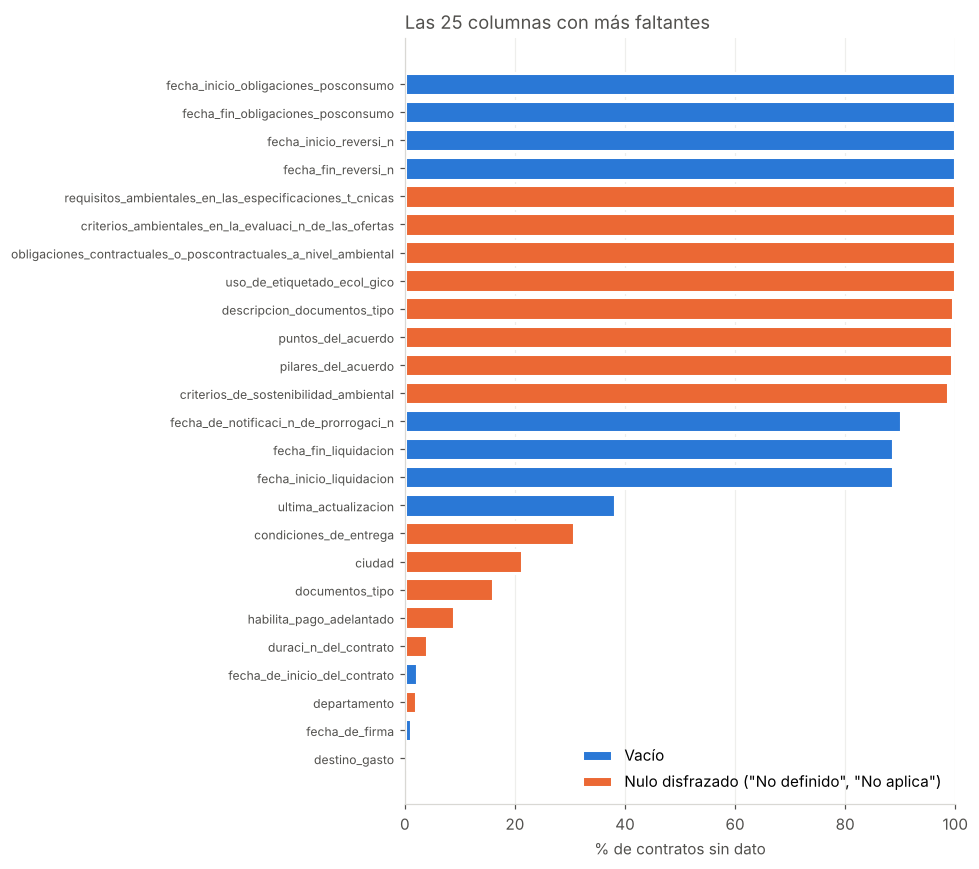

In [5]:
top = comp[comp["informado_%"] < 100].head(25).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(top.index, top["vacio_%"], color=AZUL, label="Vacío", edgecolor="white", linewidth=2)
ax.barh(top.index, top["disfrazado_%"], left=top["vacio_%"], color=NARANJA,
        label="Nulo disfrazado (\"No definido\", \"No aplica\")", edgecolor="white", linewidth=2)
ax.set_xlim(0, 100)
ax.set_xlabel("% de contratos sin dato")
ax.set_title("Las 25 columnas con más faltantes", loc="left", color=TEXTO)
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=8)
ax.legend(loc="lower right", frameon=False)
fig.tight_layout()
fig.savefig(OUT / "01_completitud.png", bbox_inches="tight")
plt.show()

Lectura:
- **Campos ambientales y del acuerdo de paz** (`criterios_*`, `puntos_del_acuerdo`, `pilares_del_acuerdo`) están casi 100 % en "No aplica" / "No definido". No sirven para análisis en este dataset.
- **Fechas de reversión y de posconsumo** están 100 % vacías: son columnas muertas.
- **`ultima_actualizacion` falta en el 38 %**, lo que limita medir la oportunidad.
- **`ciudad` (21 %) y `departamento` (2 %)** vienen como "No Definido": afecta cualquier análisis territorial.
- Las fechas de **liquidación** faltan en el 89 %. Es esperable en contratos que aún no terminan, así que esa regla debe depender del estado del contrato.

In [6]:
# Completitud de los campos personales (medida con las banderas, sin el dato)
(df[banderas].mean() * 100).round(1).sort_values().rename("informado_%").to_frame()

,informado_%
nombre_ordenador_de_pago_informado,17.1
tipo_de_documento_ordenador_de_pago_informado,17.1
n_mero_de_documento_ordenador_de_pago_informado,17.1
n_mero_de_cuenta_informado,31.6
nombre_del_banco_informado,32.5
tipo_de_cuenta_informado,32.7
tipo_de_identificaci_n_representante_legal_informado,35.2
identificaci_n_representante_legal_informado,36.0
domicilio_representante_legal_informado,36.6
tipo_de_documento_supervisor_informado,66.6


## 4. Validez: formatos, rangos y dominios

### 4.1 Fechas

In [7]:
FECHAS = ["fecha_de_firma", "fecha_de_inicio_del_contrato", "fecha_de_fin_del_contrato", "ultima_actualizacion"]
f = {c: pd.to_datetime(df[c].replace("", None), errors="coerce") for c in FECHAS}
pd.DataFrame({
    "vacias": {c: (df[c].str.strip() == "").sum() for c in FECHAS},
    "no_parseables": {c: (f[c].isna() & (df[c].str.strip() != "")).sum() for c in FECHAS},
    "minima": {c: f[c].min() for c in FECHAS},
    "maxima": {c: f[c].max() for c in FECHAS},
    "posteriores_al_corte": {c: (f[c] > FECHA_CORTE).sum() for c in FECHAS},
})

,vacias,no_parseables,minima,maxima,posteriores_al_corte
fecha_de_firma,581,0,2016-01-13 17:37:06.671,2026-10-24 17:18:21.007,0
fecha_de_inicio_del_contrato,1111,0,2016-01-14 17:00:00.000,2026-10-24 07:00:00.000,0
fecha_de_fin_del_contrato,1,0,2016-08-29 17:00:00.000,2048-06-03 00:00:00.000,5114
ultima_actualizacion,19047,0,2016-08-23 10:46:06.158,2026-10-25 10:17:39.700,0


In [8]:
fin = f["fecha_de_fin_del_contrato"]
largos = fin > FECHA_CORTE + pd.DateOffset(years=10)
print(f"Contratos que terminan después de 2036: {largos.sum()}")
df.loc[largos, ["tipo_de_contrato", "fecha_de_inicio_del_contrato", "fecha_de_fin_del_contrato", "duraci_n_del_contrato"]].head(10)

Contratos que terminan después de 2036: 3


,tipo_de_contrato,fecha_de_inicio_del_contrato,fecha_de_fin_del_contrato,duraci_n_del_contrato
8806,Otro,2022-02-24T12:00:00.000,2042-02-24T23:59:00.000,20 Año(s)
40233,Otro,2024-04-17T10:00:00.000,2044-04-29T23:59:00.000,20 Año(s)
47279,Consultoría,2023-07-10T13:00:00.000,2048-06-03T00:00:00.000,25 Año(s)


Todas las fechas tienen formato válido; el problema no es el formato sino la coherencia (sección 5). Las 5.114 fechas de fin posteriores al corte son normales: son contratos en ejecución. Solo 3 terminan después de 2036 (20 y 25 años) y su duración declarada coincide con las fechas, así que parecen reales; aun así, una consultoría a 25 años merece una revisión de negocio.

### 4.2 Valores monetarios

In [9]:
VALORES = ["valor_del_contrato", "valor_pagado", "valor_facturado", "valor_pendiente_de_pago"]
v = {c: pd.to_numeric(df[c], errors="coerce") for c in VALORES}
pd.DataFrame({
    "no_numericos": {c: v[c].isna().sum() for c in VALORES},
    "en_cero": {c: (v[c] == 0).sum() for c in VALORES},
    "negativos": {c: (v[c] < 0).sum() for c in VALORES},
    "mediana": {c: v[c].median() for c in VALORES},
    "p99": {c: v[c].quantile(0.99) for c in VALORES},
    "maximo": {c: v[c].max() for c in VALORES},
}).style.format("{:,.0f}")

,no_numericos,en_cero,negativos,mediana,p99,maximo
valor_del_contrato,0,364,0,"19,800,000","1,755,677,510","541,389,953,817"
valor_pagado,0,"24,877",0,"1,045,300","388,992,570","67,067,689,018"
valor_facturado,0,"21,507",0,"5,700,000","496,099,505","220,587,214,769"
valor_pendiente_de_pago,0,"15,463",29,"6,300,000","1,247,404,966","541,389,953,817"


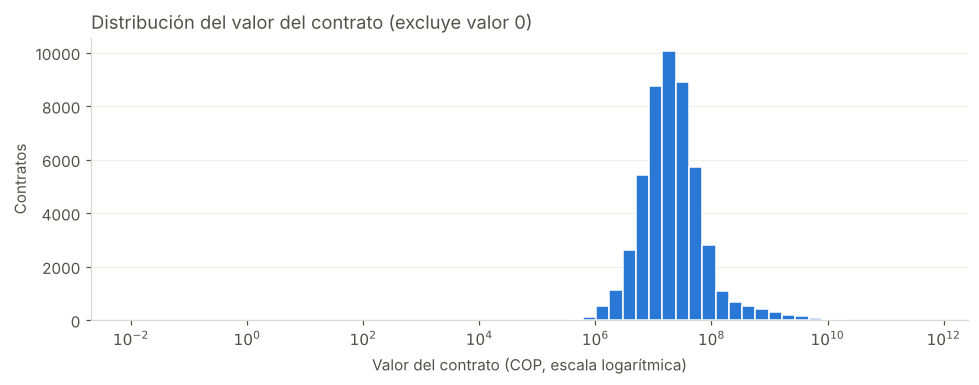

Contratos con valor 0: 364
Contratos con valor entre 0 y 1.000 pesos: 26 (de ellos, exactamente 1 peso: 18)
Contratos por encima de 100.000 millones: 6


,nombre_entidad,tipo_de_contrato,valor_del_contrato
8194,INVIAS,Obra,541389953817
27797,INVIAS,Obra,285778659380
593,INVIAS,Obra,233344263279
39802,FONDO ROTATORIO**,Prestación de servicios,220646722131
1724,INVIAS,Acuerdo Marco de Precios,133242583045


In [10]:
import numpy as np

valor = v["valor_del_contrato"]
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(np.log10(valor[valor > 0]), bins=60, color=AZUL, edgecolor="white", linewidth=1)
ticks = range(-2, 13, 2)
ax.set_xticks(list(ticks), [f"$10^{{{t}}}$" for t in ticks])
ax.set_xlabel("Valor del contrato (COP, escala logarítmica)")
ax.set_ylabel("Contratos")
ax.set_title("Distribución del valor del contrato (excluye valor 0)", loc="left", color=TEXTO)
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(OUT / "01_valor_contrato.png", bbox_inches="tight")
plt.show()

print(f"Contratos con valor 0: {(valor == 0).sum()}")
print(f"Contratos con valor entre 0 y 1.000 pesos: {((valor > 0) & (valor < 1000)).sum()} (de ellos, exactamente 1 peso: {(valor == 1).sum()})")
print(f"Contratos por encima de 100.000 millones: {(valor > 1e11).sum()}")
df.loc[valor.nlargest(5).index, ["nombre_entidad", "tipo_de_contrato", "valor_del_contrato"]]

- No hay valores negativos ni no numéricos: el tipo está bien.
- **364 contratos tienen valor 0** y **26 valen menos de 1.000 pesos**, la mayoría exactamente 1 peso. Son valores de relleno: alguien tuvo que llenar el campo sin tener el dato. Solo el comodato justifica un valor nulo.
- La distribución tiene una cola muy larga: la mediana ronda los 20 millones y el máximo pasa de 540.000 millones (una obra de INVIAS). Los extremos no son errores por sí mismos, pero son los primeros candidatos para la dimensión de exactitud.

### 4.3 Documento del proveedor

In [11]:
cc = df["tipodocproveedor"] == "Cédula de Ciudadanía"
print("Longitud del documento cuando es cédula de ciudadanía:")
print(df.loc[cc, "documento_proveedor_longitud"].value_counts().sort_index().to_string())
print()
print(f"Documentos con caracteres distintos de dígitos: {(~df['documento_proveedor_solo_digitos'].fillna(False)).sum()}")
print()
print(df["tipodocproveedor"].value_counts().to_string())

Longitud del documento cuando es cédula de ciudadanía:
documento_proveedor_longitud
6        12
7      1660
8     18760
9        93
10    21653
11       39
12        8
13       16
14        1
17        1
18        1
19        1
23        1

Documentos con caracteres distintos de dígitos: 254

tipodocproveedor
Cédula de Ciudadanía               42246
NIT                                 7463
Otro                                 119
No Definido                           91
Cédula de Extranjería                 60
Permiso por Protección Temporal       13
Tarjeta de Identidad                   5
Permiso especial de permanencia        2
Pasaporte                              1


- Una cédula de ciudadanía colombiana tiene entre 6 y 10 dígitos. Hay **68 cédulas con 11 dígitos o más**, que no son válidas.
- **254 documentos** tienen caracteres que no son dígitos (puntos, guiones, letras).
- **5 contratos** están adjudicados a una **Tarjeta de Identidad**, que en Colombia corresponde a menores de edad. Es una anomalía de negocio que hay que revisar.

### 4.4 Dominios de las categorías

In [12]:
for c in ["estado_contrato", "tipo_de_contrato", "modalidad_de_contratacion", "es_pyme", "orden", "sector"]:
    vc = df[c].value_counts()
    print(f"{c}: {len(vc)} valores")
    print("  " + " · ".join(f"{k} ({n:,})" for k, n in vc.head(12).items()))
    print()

estado_contrato: 10 valores
  En ejecución (15,467) · Cerrado (15,222) · Modificado (9,554) · terminado (7,032) · Aprobado (1,830) · enviado Proveedor (382) · cedido (250) · En aprobación (200) · Suspendido (62) · Prorrogado (1)

tipo_de_contrato: 20 valores
  Prestación de servicios (43,069) · Otro (1,750) · Decreto 092 de 2017 (1,696) · Suministros (1,233) · Compraventa (976) · Obra (450) · Arrendamiento de inmuebles (384) · Comodato (105) · Interventoría (101) · Consultoría (95) · Seguros (83) · Arrendamiento de muebles (16)

modalidad_de_contratacion: 14 valores
  Contratación directa (38,124) · Contratación régimen especial (6,723) · Mínima cuantía (2,731) · Contratación Directa (con ofertas) (658) · Selección Abreviada de Menor Cuantía (522) · Contratación régimen especial (con ofertas) (446) · Selección abreviada subasta inversa (437) · Licitación pública (146) · Concurso de méritos abierto (125) · Licitación pública Obra Publica (69) · Seleccion Abreviada Menor Cuantia Sin Mani

In [13]:
print(f"Departamentos distintos: {df['departamento'].nunique()} (Colombia tiene 32 + Bogotá D.C. = 33)")
print(sorted(df["departamento"].unique()))

Departamentos distintos: 34 (Colombia tiene 32 + Bogotá D.C. = 33)
['Amazonas', 'Antioquia', 'Arauca', 'Atlántico', 'Bolívar', 'Boyacá', 'Caldas', 'Caquetá', 'Casanare', 'Cauca', 'Cesar', 'Chocó', 'Cundinamarca', 'Córdoba', 'Distrito Capital de Bogotá', 'Guainía', 'Guaviare', 'Huila', 'La Guajira', 'Magdalena', 'Meta', 'Nariño', 'No Definido', 'Norte de Santander', 'Putumayo', 'Quindío', 'Risaralda', 'San Andrés, Providencia y Santa Catalina', 'Santander', 'Sucre', 'Tolima', 'Valle del Cauca', 'Vaupés', 'Vichada']


- **`estado_contrato` mezcla mayúsculas y minúsculas** (`Cerrado` y `terminado`, `En ejecución` y `enviado Proveedor`). Si alguien agrupa sin normalizar no pasa nada aquí, pero es señal de que los valores no vienen de una lista controlada.
- **`departamento` tiene 34 valores**: los 33 reales más `No Definido`.
- **`modalidad_de_contratacion`** distingue `Contratación directa` de `Contratación Directa (con ofertas)`: son modalidades distintas, pero el uso de mayúsculas tampoco es consistente.
- **`sector`** también mezcla mayúsculas (`defensa`, `deportes` frente a `Educación Nacional`) y usa `No aplica/No pertenece` en 7.703 contratos.
- **`tipo_de_contrato`** usa `Decreto 092 de 2017` como tipo, cuando es una norma y no un tipo de contrato, y 1.750 contratos van como `Otro`.

## 5. Consistencia entre campos

In [14]:
firma = f["fecha_de_firma"].dt.normalize()
inicio = f["fecha_de_inicio_del_contrato"].dt.normalize()
pagado = v["valor_pagado"]
facturado = v["valor_facturado"]

checks = {
    "Fin antes del inicio": fin < inicio,
    "Inicio antes de la firma": inicio < firma,
    "Pagado mayor que el valor del contrato": pagado > valor,
    "Facturado mayor que el valor del contrato": facturado > valor,
    "Cerrado o terminado sin fecha de fin pasada": df["estado_contrato"].str.lower().isin(["cerrado", "terminado"]) & (fin > FECHA_CORTE),
}
consist = pd.DataFrame({"contratos": {k: s.sum() for k, s in checks.items()}})
consist["%"] = (consist["contratos"] / len(df) * 100).round(2)
consist

,contratos,%
Fin antes del inicio,4,0.01
Inicio antes de la firma,1820,3.64
Pagado mayor que el valor del contrato,29,0.06
Facturado mayor que el valor del contrato,39,0.08
Cerrado o terminado sin fecha de fin pasada,51,0.10


### 5.1 Duración declarada frente a las fechas

`duraci_n_del_contrato` es texto (`"118 Dia(s)"`, `"5 Mes(es)"`). Se convierte a días y se compara con la diferencia entre inicio y fin.

In [15]:
dur = df["duraci_n_del_contrato"].str.extract(r"(?P<n>\d+)\s*(?P<unidad>Dia|Mes|Año|Semana|Hora)", expand=True)
factor = {"Dia": 1, "Semana": 7, "Mes": 30.44, "Año": 365.25, "Hora": 1 / 24}
dur_dias = pd.to_numeric(dur["n"]) * dur["unidad"].map(factor)
dias_fechas = (fin - inicio).dt.days

print("Unidades usadas:", df["duraci_n_del_contrato"].str.extract(r"\d+\s*(.*)")[0].value_counts().to_dict())
comparables = dur_dias.notna() & dias_fechas.notna()
diferencia = (dias_fechas - dur_dias).abs()
print(f"Contratos comparables: {comparables.sum():,}")
print(f"Difieren más de 30 días: {(diferencia[comparables] > 30).sum():,} "
      f"({(diferencia[comparables] > 30).mean() * 100:.1f} %)")

Unidades usadas: {'Dia(s)': 26964, 'Mes(es)': 18673, 'Año(s)': 182, 'Hora(s)': 57, 'Semana(s)': 32}
Contratos comparables: 44,798
Difieren más de 30 días: 5,068 (11.3 %)


Parte de esa diferencia es legítima: las prórrogas amplían la fecha de fin sin cambiar la duración inicial (ver `dias_adicionados`). En la Fase 2 la regla debe descontar los días adicionados antes de marcar un contrato como inconsistente.

## 6. Unicidad

In [16]:
print(f"id_contrato duplicados: {df['id_contrato'].duplicated().sum()}")
dup_ref = df.duplicated(["nit_entidad", "referencia_del_contrato"], keep=False)
print(f"Contratos que comparten entidad y referencia: {dup_ref.sum()}")
df.loc[dup_ref].sort_values(["nit_entidad", "referencia_del_contrato"])[
    ["nit_entidad", "referencia_del_contrato", "id_contrato", "estado_contrato", "valor_del_contrato"]
].head(8)

id_contrato duplicados: 0
Contratos que comparten entidad y referencia: 67


,nit_entidad,referencia_del_contrato,id_contrato,estado_contrato,valor_del_contrato
11855,813001950,002-2024,CO1.PCCNTR.5760894,terminado,14280000
29994,813001950,002-2024,CO1.PCCNTR.5989875,Modificado,2691000
21767,890201222,1056,CO1.PCCNTR.7469744,terminado,24600000
42576,890201222,1056,CO1.PCCNTR.6046445,En ejecución,10000000
23734,890201222,1144,CO1.PCCNTR.7488913,terminado,36000000
38233,890201222,1144,CO1.PCCNTR.8997320,En ejecución,27600000
3918,890201222,1697,CO1.PCCNTR.3478047,Cerrado,24000000
7424,890201222,1697,CO1.PCCNTR.6494101,Modificado,27833333.34


`id_contrato` es único, como se espera de la llave de la plataforma. Pero **67 contratos comparten entidad y número de referencia con otro**. En los ejemplos los valores y estados son distintos, así que lo más probable es que la entidad reutilice la numeración (por ejemplo cada año) y no que el contrato esté duplicado. Aun así, la referencia no sirve como identificador del contrato, y eso hay que saberlo antes de cruzar con otros sistemas.

## 7. Oportunidad

In [17]:
ult = f["ultima_actualizacion"]
edad = (FECHA_CORTE - ult).dt.days
print(f"Sin fecha de última actualización: {ult.isna().mean() * 100:.1f} %")
en_ejec = df["estado_contrato"] == "En ejecución"
print(f"Contratos en ejecución sin actualización en más de 1 año: "
      f"{(en_ejec & (edad > 365)).sum():,} de {en_ejec.sum():,}")

Sin fecha de última actualización: 38.1 %
Contratos en ejecución sin actualización en más de 1 año: 45 de 15,467


La oportunidad casi no se puede medir con este dataset: más de un tercio de los contratos no tiene fecha de última actualización. Eso es en sí un hallazgo para el plan de mejora.

## 8. Resumen de hallazgos → reglas de la Fase 2

In [18]:
perfil = pd.DataFrame({
    "tipo_origen": "texto",
    "vacio_%": comp["vacio_%"],
    "disfrazado_%": comp["disfrazado_%"],
    "informado_%": comp["informado_%"],
    "valores_distintos": {c: df[c].nunique() for c in texto},
}).sort_values("informado_%")
perfil.to_csv(OUT / "01_perfil_columnas.csv")
print(f"Perfil por columna guardado en outputs/01_perfil_columnas.csv ({len(perfil)} columnas)")

Perfil por columna guardado en outputs/01_perfil_columnas.csv (77 columnas)


| Dimensión | Hallazgo | Regla candidata |
|---|---|---|
| Completitud | Nulos disfrazados ("No definido", "No aplica") en 20 columnas | Tratar esos textos como nulos antes de medir |
| Completitud | `ultima_actualizacion` falta en el 38 %; `ciudad` en el 21 % | Completitud mínima por campo crítico |
| Completitud | 8 columnas casi vacías (criterios ambientales, acuerdo de paz, documentos tipo) y 4 fechas 100 % vacías | Excluir del score y reportarlas como columnas muertas |
| Validez | Cédulas de 11 dígitos o más y documentos con caracteres no numéricos | Formato del documento según su tipo |
| Validez | 364 contratos con valor 0 y 26 con valores de relleno (1 peso) | Valor mínimo plausible salvo tipos que lo admitan (comodato) |
| Validez | Estados, modalidades y sectores con mayúsculas inconsistentes; `Decreto 092 de 2017` como tipo | Dominio controlado por campo categórico |
| Consistencia | Inicio antes de la firma, fin antes del inicio, pagado mayor que el valor | Reglas de orden entre fechas y entre valores |
| Consistencia | Duración declarada distinta de la duración por fechas | Comparar descontando `dias_adicionados` |
| Unicidad | 67 contratos comparten entidad y referencia | Detectar duplicados de negocio por (entidad, referencia, proveedor, valor) |
| Exactitud | Cola extrema de valores (> 100.000 millones) | Revisión de atípicos por tipo de contrato |
| Oportunidad | Contratos en ejecución sin actualizar en más de un año | Antigüedad máxima de actualización según estado |
| Negocio | 5 contratos adjudicados a una Tarjeta de Identidad | Alerta de revisión manual |

Las cifras exactas de cada fila están en las celdas de arriba. En la Fase 2 cada regla se implementa en `src/` con su umbral, y en la Fase 3 se combinan en el DQ Score.